# TA-03: Prediksi Niat Pembelian Pengunjung E-Commerce dengan Regresi Logistik

**Mata Praktikum:** Pembelajaran Mesin  
**Dataset:** Online Shoppers Purchasing Intention (12.330 sesi pengunjung)  
**Target:** `Revenue` (1 = pengunjung membeli, 0 = tidak membeli)

Alur notebook:
1. Import library dan memuat data
2. Pengecekan kualitas data
3. EDA (grafik disimpan ke folder `images/`)
4. Preprocessing (duplikat, encoding, split, scaling, SMOTE)
5. Pemodelan: tanpa SMOTE vs dengan SMOTE
6. Evaluasi: Confusion Matrix, Precision, Recall, F1, ROC-AUC
7. Analisis threshold
8. Interpretasi koefisien model
9. Menyimpan model untuk aplikasi Flask

## 1. Import library dan memuat data

In [27]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve,
                             precision_score, recall_score, f1_score,
                             accuracy_score)
from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid")

# ---------------------------------------------------------------
# Cari folder proyek dan file CSV secara otomatis
# ---------------------------------------------------------------
def find_project_root_and_csv():
    start = Path.cwd().resolve()
    for folder in [start, *start.parents]:
        data_dir = folder / "data"
        if data_dir.is_dir():
            matches = sorted(data_dir.glob("*online_shoppers_intention*.csv"))
            if matches:
                return folder, matches[0]
    raise FileNotFoundError(
        f"CSV tidak ditemukan. Folder kerja saat ini: {start}\n"
        "Pastikan file ada di folder 'data' proyek, "
        "dengan nama yang mengandung 'online_shoppers_intention'."
    )

ROOT, DATA_PATH = find_project_root_and_csv()
MODEL_DIR = ROOT / "model"
IMG_DIR = ROOT / "images"
MODEL_DIR.mkdir(exist_ok=True)
IMG_DIR.mkdir(exist_ok=True)

print("Folder proyek:", ROOT)
print("File data    :", DATA_PATH.name)

RANDOM_STATE = 42

Folder proyek: D:\Tugas semester 5\pemodelan mesin\TP DAN TA-03\TA03-Regresi logistik
File data    : online_shoppers_intention.csv


In [28]:
df = pd.read_csv(DATA_PATH)
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [30]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


## 2. Pengecekan kualitas data

In [31]:
print("Total missing value  :", df.isnull().sum().sum())
print("Jumlah baris duplikat:", df.duplicated().sum())

print("\nDistribusi target (jumlah):")
print(df["Revenue"].value_counts())
print("\nDistribusi target (proporsi):")
print(df["Revenue"].value_counts(normalize=True).round(3))

Total missing value  : 0
Jumlah baris duplikat: 125

Distribusi target (jumlah):
Revenue
False    10422
True      1908
Name: count, dtype: int64

Distribusi target (proporsi):
Revenue
False    0.845
True     0.155
Name: proportion, dtype: float64


**Catatan untuk laporan:** tidak ada missing value, ada duplikat yang perlu dihapus, 
dan kelas target tidak seimbang (*class imbalance*), sehingga akurasi saja tidak cukup sebagai metrik.

## 3. Exploratory Data Analysis (EDA)

### 3.1 Distribusi target

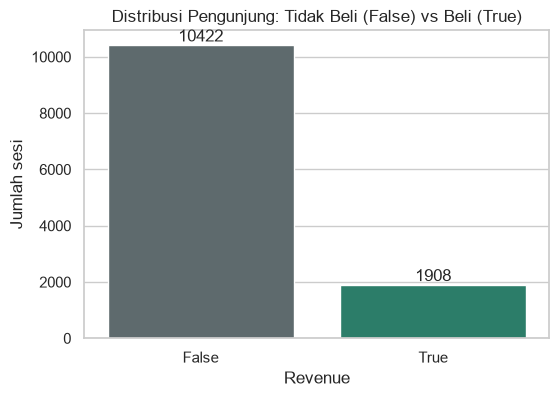

In [32]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="Revenue", data=df, hue="Revenue", palette=["#5B6B70", "#1F8A70"], legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribusi Pengunjung: Tidak Beli (False) vs Beli (True)")
plt.xlabel("Revenue")
plt.ylabel("Jumlah sesi")
plt.savefig(IMG_DIR / "01_distribusi_target.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.2 Distribusi fitur numerik utama

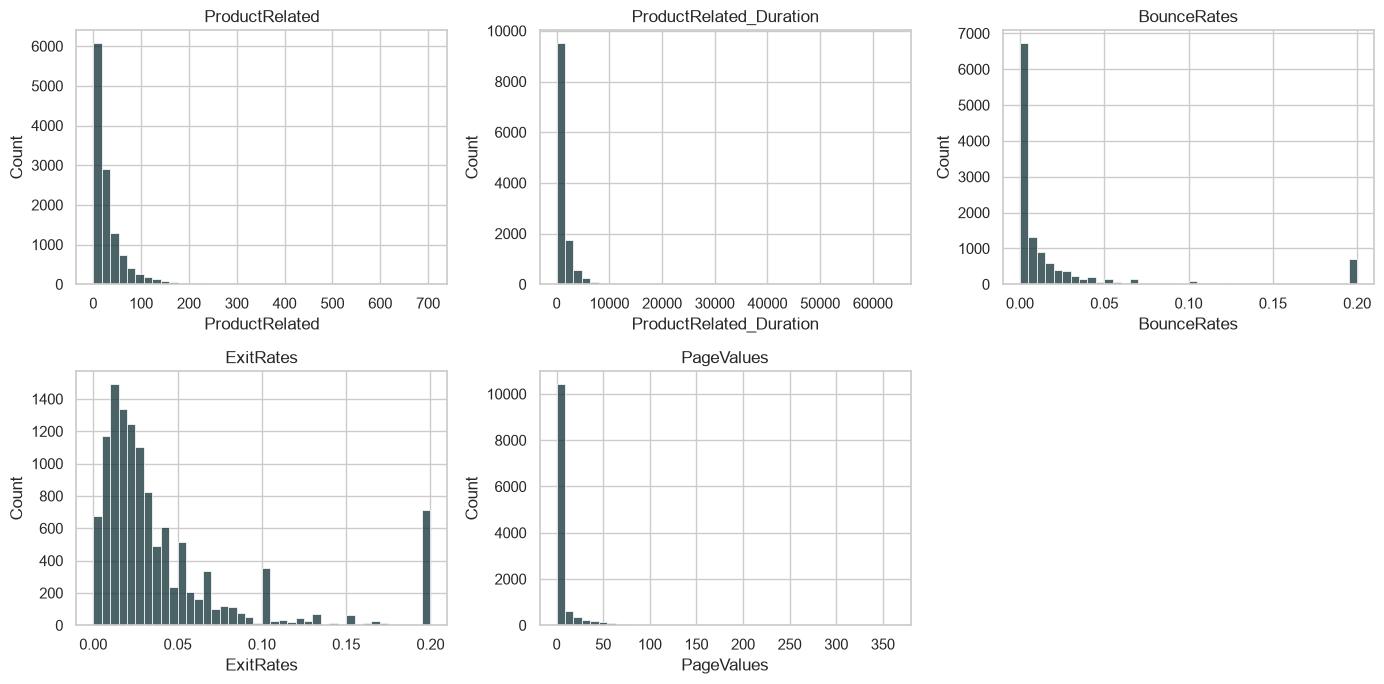

In [33]:
num_view = ["ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), num_view):
    sns.histplot(df[col], bins=40, ax=ax, color="#0F2E33")
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig(IMG_DIR / "02_distribusi_fitur_numerik.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3 Fitur numerik vs target

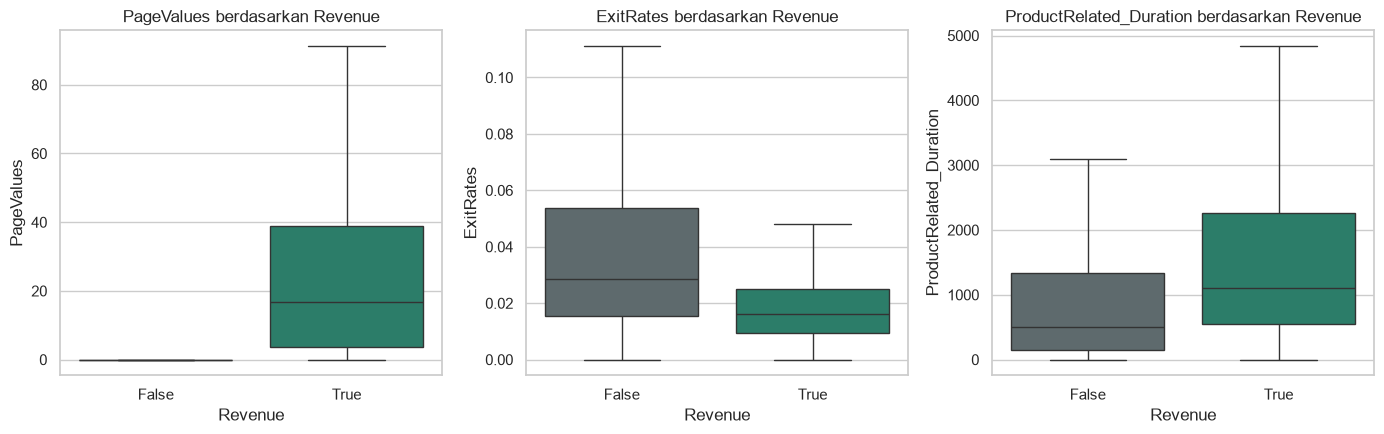

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, col in zip(axes, ["PageValues", "ExitRates", "ProductRelated_Duration"]):
    sns.boxplot(x="Revenue", y=col, data=df, ax=ax, showfliers=False,
                hue="Revenue", palette=["#5B6B70", "#1F8A70"], legend=False)
    ax.set_title(f"{col} berdasarkan Revenue")
plt.tight_layout()
plt.savefig(IMG_DIR / "03_boxplot_fitur_vs_target.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.4 Tingkat pembelian berdasarkan bulan, tipe pengunjung, dan akhir pekan

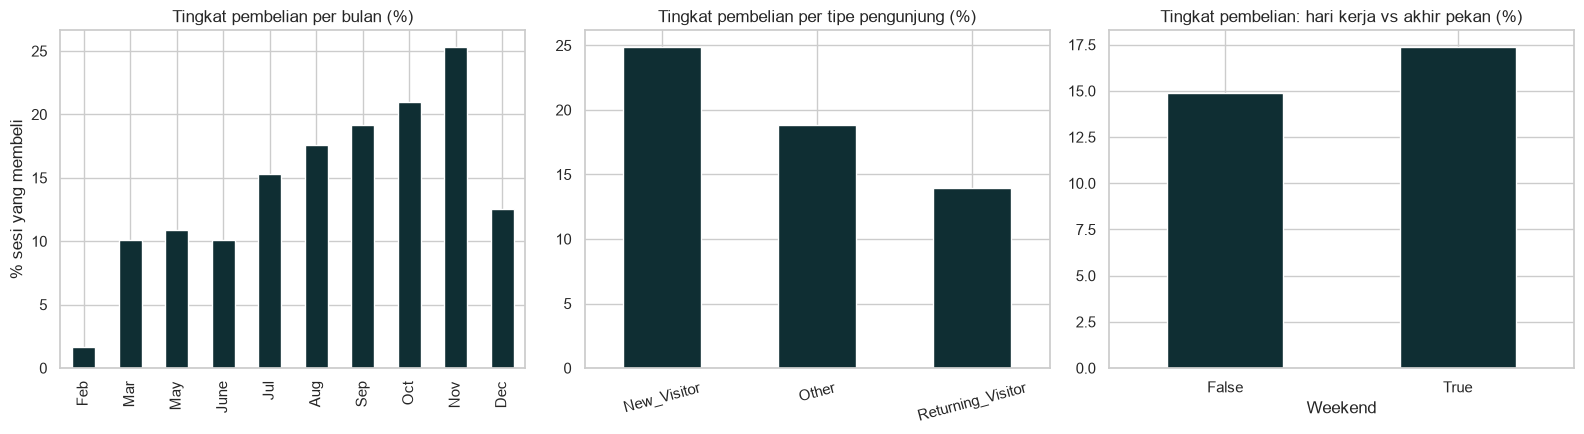

In [35]:
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
rate_month = (df.groupby("Month")["Revenue"].mean().reindex(month_order) * 100)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

rate_month.plot(kind="bar", ax=axes[0], color="#0F2E33")
axes[0].set_title("Tingkat pembelian per bulan (%)")
axes[0].set_ylabel("% sesi yang membeli")
axes[0].set_xlabel("")

(df.groupby("VisitorType")["Revenue"].mean() * 100).plot(kind="bar", ax=axes[1], color="#0F2E33")
axes[1].set_title("Tingkat pembelian per tipe pengunjung (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)

(df.groupby("Weekend")["Revenue"].mean() * 100).plot(kind="bar", ax=axes[2], color="#0F2E33")
axes[2].set_title("Tingkat pembelian: hari kerja vs akhir pekan (%)")
axes[2].set_xlabel("Weekend")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(IMG_DIR / "04_tingkat_pembelian_kategori.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.5 Korelasi antar fitur numerik

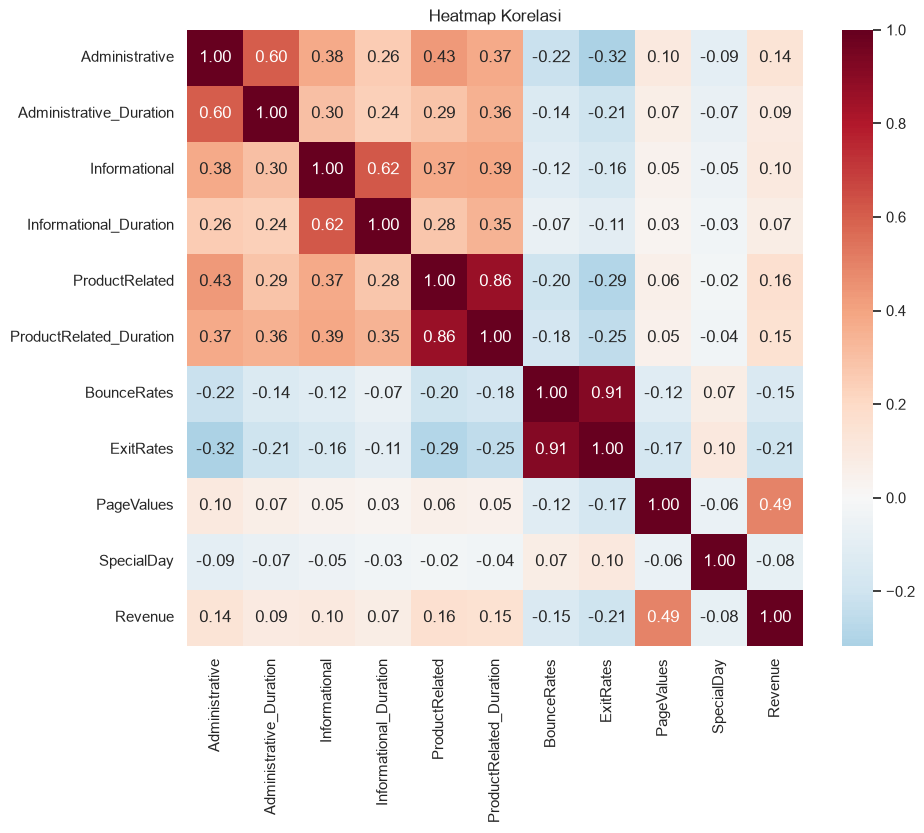

In [36]:
corr_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
             "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
             "PageValues", "SpecialDay"]
corr = df[corr_cols].assign(Revenue=df["Revenue"].astype(int)).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Heatmap Korelasi")
plt.savefig(IMG_DIR / "05_korelasi_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Catatan untuk laporan:** `BounceRates` dan `ExitRates` berkorelasi sangat tinggi (multikolinearitas), 
begitu juga durasi dengan jumlah halaman. Regresi Logistik masih bisa dipakai, tetapi koefisien 
fitur yang berkorelasi tinggi perlu diinterpretasi dengan hati-hati.

## 4. Preprocessing

Langkah-langkah:
1. Hapus baris duplikat
2. Ubah target dan `Weekend` menjadi 0/1
3. One-hot encoding untuk kolom kategorikal. `OperatingSystems`, `Browser`, `Region`, dan `TrafficType` 
   berisi angka tetapi hanya kode kategori, sehingga harus di-encode (bukan di-scale)
4. Split data **dulu**, baru scaling dan SMOTE hanya pada data latih (mencegah *data leakage*)

In [37]:
df_clean = df.drop_duplicates().copy()
print("Setelah hapus duplikat:", df_clean.shape)

df_clean["Revenue"] = df_clean["Revenue"].astype(int)
df_clean["Weekend"] = df_clean["Weekend"].astype(int)

# Simpan daftar kategori untuk dropdown di aplikasi
MONTH_ORDER = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
months_present = [m for m in MONTH_ORDER if m in df_clean["Month"].unique()]
months_present += sorted(set(df_clean["Month"].unique()) - set(months_present))
visitor_types = sorted(df_clean["VisitorType"].unique().tolist())

cat_cols = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
df_model = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True, dtype=int)
print("Ukuran setelah encoding:", df_model.shape)

num_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
            "PageValues", "SpecialDay"]

Setelah hapus duplikat: (12205, 18)
Ukuran setelah encoding: (12205, 69)


In [38]:
X = df_model.drop(columns="Revenue")
y = df_model["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Data latih :", X_train.shape, "| proporsi beli:", round(y_train.mean(), 3))
print("Data uji   :", X_test.shape, "| proporsi beli:", round(y_test.mean(), 3))

# Nilai median (data mentah) untuk mengisi fitur yang tidak ada di form aplikasi
defaults = {c: float(X_train[c].median()) for c in num_cols}

Data latih : (9764, 68) | proporsi beli: 0.156
Data uji   : (2441, 68) | proporsi beli: 0.156


In [39]:
scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])   # fit hanya di data latih
X_test_s[num_cols] = scaler.transform(X_test[num_cols])         # data uji hanya transform

smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train_s, y_train)  # SMOTE hanya di data latih

print("Sebelum SMOTE:", y_train.value_counts().to_dict())
print("Sesudah SMOTE:", y_train_sm.value_counts().to_dict())

Sebelum SMOTE: {0: 8238, 1: 1526}
Sesudah SMOTE: {1: 8238, 0: 8238}


## 5. Pemodelan Regresi Logistik

Dua model dilatih sebagai pembanding: tanpa SMOTE (baseline) dan dengan SMOTE.

In [40]:
model_base = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
model_base.fit(X_train_s, y_train)

model_smote = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
model_smote.fit(X_train_sm, y_train_sm)

print("Kedua model selesai dilatih.")

Kedua model selesai dilatih.


## 6. Evaluasi model

In [41]:
def evaluate(model, X_eval, y_eval, threshold=0.5):
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_eval, pred).ravel()
    return {
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred),
        "F1": f1_score(y_eval, pred),
        "AUC": roc_auc_score(y_eval, proba),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

compare = pd.DataFrame({
    "Tanpa SMOTE": evaluate(model_base, X_test_s, y_test),
    "Dengan SMOTE": evaluate(model_smote, X_test_s, y_test),
}).T
compare.round(3)

,Accuracy,Precision,Recall,F1,AUC,TN,FP,FN,TP
Tanpa SMOTE,0.888,0.757,0.416,0.537,0.900,2008.0,51.0,223.0,159.0
Dengan SMOTE,0.850,0.516,0.683,0.588,0.877,1814.0,245.0,121.0,261.0


In [42]:
print("=== Classification Report: TANPA SMOTE ===")
print(classification_report(y_test, model_base.predict(X_test_s),
                            target_names=["Tidak Beli", "Beli"], digits=3))
print("=== Classification Report: DENGAN SMOTE ===")
print(classification_report(y_test, model_smote.predict(X_test_s),
                            target_names=["Tidak Beli", "Beli"], digits=3))

=== Classification Report: TANPA SMOTE ===
              precision    recall  f1-score   support

  Tidak Beli      0.900     0.975     0.936      2059
        Beli      0.757     0.416     0.537       382

    accuracy                          0.888      2441
   macro avg      0.829     0.696     0.737      2441
weighted avg      0.878     0.888     0.874      2441

=== Classification Report: DENGAN SMOTE ===
              precision    recall  f1-score   support

  Tidak Beli      0.937     0.881     0.908      2059
        Beli      0.516     0.683     0.588       382

    accuracy                          0.850      2441
   macro avg      0.727     0.782     0.748      2441
weighted avg      0.871     0.850     0.858      2441



**Catatan untuk laporan:** bandingkan Recall kelas "Beli" pada kedua model. 
Jelaskan mengapa akurasi tanpa SMOTE terlihat tinggi tetapi Recall rendah, dan apa konsekuensinya 
(False Negative = pengunjung yang akan membeli tetapi tidak terdeteksi).

### 6.1 Confusion Matrix (kedua model)

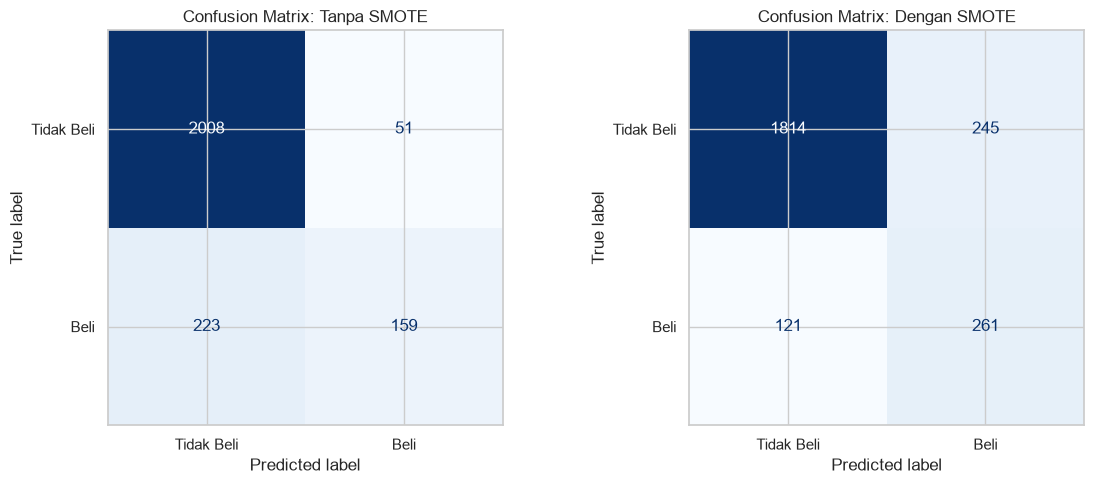

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, m) in zip(axes, [("Tanpa SMOTE", model_base), ("Dengan SMOTE", model_smote)]):
    cm = confusion_matrix(y_test, m.predict(X_test_s))
    ConfusionMatrixDisplay(cm, display_labels=["Tidak Beli", "Beli"]).plot(
        cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Confusion Matrix: {name}")
plt.tight_layout()
plt.savefig(IMG_DIR / "06_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.2 Kurva ROC dan AUC

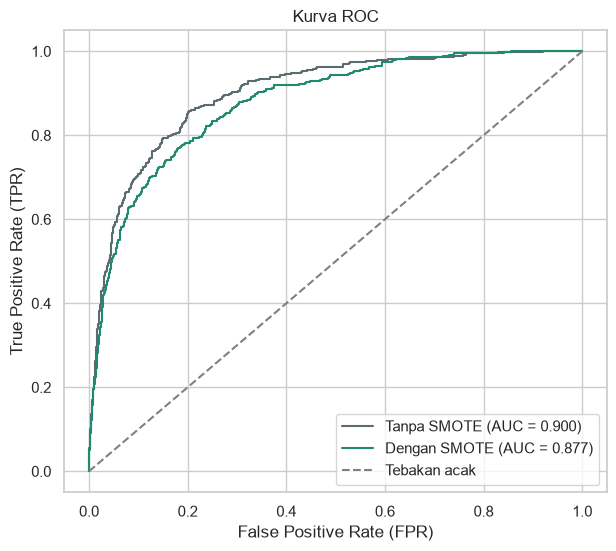

In [44]:
plt.figure(figsize=(7, 6))
for name, m, color in [("Tanpa SMOTE", model_base, "#5B6B70"), ("Dengan SMOTE", model_smote, "#1F8A70")]:
    proba = m.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, color=color, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Tebakan acak")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Kurva ROC")
plt.legend()
plt.savefig(IMG_DIR / "07_roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Analisis threshold

Threshold bawaan 0,5 belum tentu optimal. Menurunkan threshold menaikkan Recall 
(lebih banyak pembeli terdeteksi) dengan konsekuensi lebih banyak False Positive.

In [45]:
rows = {}
for t in [0.7, 0.6, 0.5, 0.4, 0.3, 0.2]:
    r = evaluate(model_smote, X_test_s, y_test, threshold=t)
    rows[t] = {k: r[k] for k in ["Precision", "Recall", "F1", "FP", "FN"]}
threshold_table = pd.DataFrame(rows).T
threshold_table.index.name = "Threshold"
threshold_table.round(3)

,Precision,Recall,F1,FP,FN
Threshold,,,,,
0.7,0.639,0.524,0.576,113.0,182.0
0.6,0.590,0.628,0.608,167.0,142.0
0.5,0.516,0.683,0.588,245.0,121.0
0.4,0.454,0.746,0.564,343.0,97.0
0.3,0.393,0.804,0.528,474.0,75.0
0.2,0.330,0.893,0.482,692.0,41.0


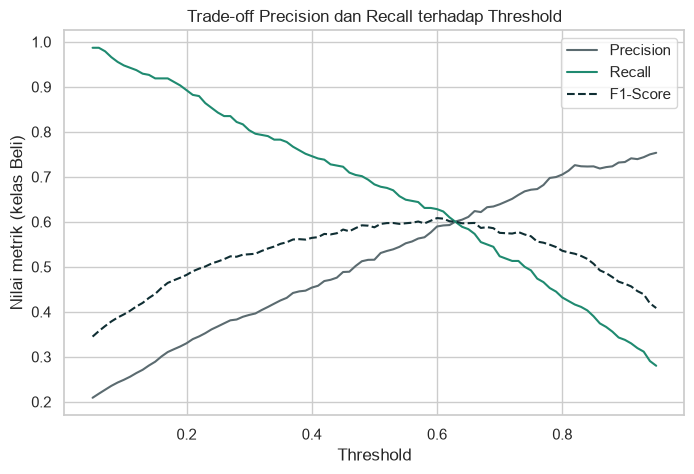

In [46]:
proba_final = model_smote.predict_proba(X_test_s)[:, 1]
ts = np.linspace(0.05, 0.95, 91)
prec = [precision_score(y_test, (proba_final >= t).astype(int), zero_division=0) for t in ts]
rec = [recall_score(y_test, (proba_final >= t).astype(int)) for t in ts]
f1s = [f1_score(y_test, (proba_final >= t).astype(int)) for t in ts]

plt.figure(figsize=(8, 5))
plt.plot(ts, prec, label="Precision", color="#5B6B70")
plt.plot(ts, rec, label="Recall", color="#1F8A70")
plt.plot(ts, f1s, label="F1-Score", color="#0F2E33", linestyle="--")
plt.xlabel("Threshold")
plt.ylabel("Nilai metrik (kelas Beli)")
plt.title("Trade-off Precision dan Recall terhadap Threshold")
plt.legend()
plt.savefig(IMG_DIR / "08_threshold_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

**Pilih threshold final** sesuai strategi bisnis dan jelaskan alasannya di laporan. 
Ubah nilai `THRESHOLD` di bawah (mis. 0.4 jika ingin Recall lebih tinggi). 
Nilai ini otomatis dipakai oleh aplikasi Flask.

In [47]:
THRESHOLD = 0.5
final_model = model_smote

final_metrics = evaluate(final_model, X_test_s, y_test, threshold=THRESHOLD)
pd.Series(final_metrics).round(3)

Accuracy        0.850
Precision       0.516
Recall          0.683
F1              0.588
AUC             0.877
TN           1814.000
FP            245.000
FN            121.000
TP            261.000
dtype: float64

## 8. Interpretasi koefisien model

Koefisien positif menaikkan peluang pembelian, koefisien negatif menurunkannya. 
Fitur numerik sudah di-scale, sehingga koefisiennya bisa dibandingkan satu sama lain. 
Kategori yang di-drop (`drop_first=True`) menjadi pembanding: bulan **Aug** dan tipe pengunjung **New_Visitor**.

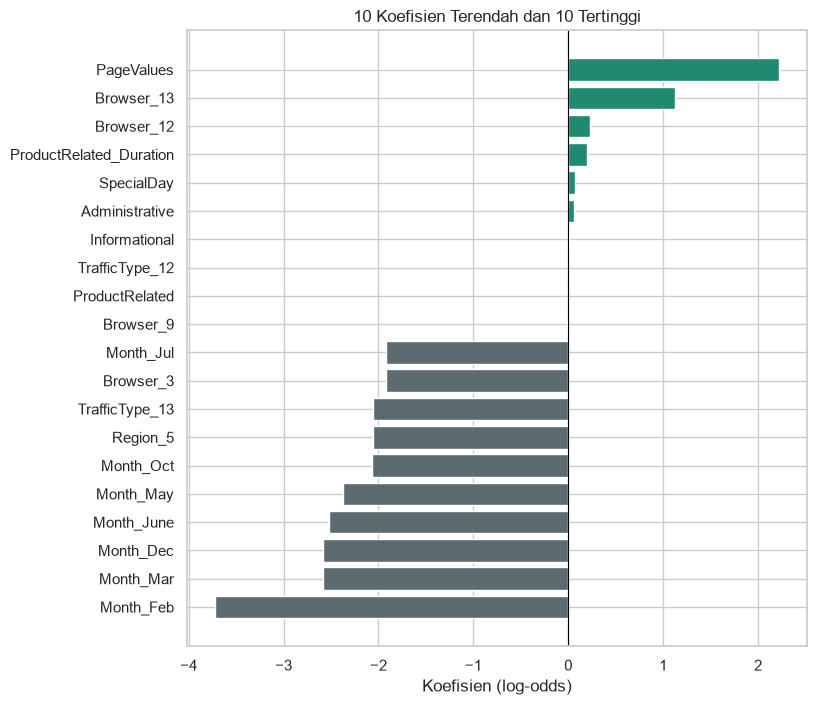

In [48]:
coef = pd.Series(final_model.coef_[0], index=X.columns).sort_values()
top = pd.concat([coef.head(10), coef.tail(10)])

plt.figure(figsize=(8, 8))
colors = ["#5B6B70" if v < 0 else "#1F8A70" for v in top.values]
plt.barh(top.index, top.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("10 Koefisien Terendah dan 10 Tertinggi")
plt.xlabel("Koefisien (log-odds)")
plt.savefig(IMG_DIR / "09_koefisien_model.png", dpi=150, bbox_inches="tight")
plt.show()

In [49]:
odds = pd.DataFrame({"Koefisien": coef, "Odds Ratio": np.exp(coef)}).sort_values("Koefisien", ascending=False)
odds.head(10).round(3)

,Koefisien,Odds Ratio
PageValues,2.221,9.218
Browser_13,1.127,3.085
Browser_12,0.232,1.261
ProductRelated_Duration,0.196,1.217
SpecialDay,0.066,1.069
Administrative,0.059,1.061
Informational,0.006,1.006
TrafficType_12,0.000,1.000
ProductRelated,-0.003,0.997
Browser_9,-0.014,0.986


## 9. Menyimpan model untuk aplikasi Flask

Semua artefak disimpan di folder `model/`. Aplikasi Flask membutuhkan: model, scaler, 
urutan kolom, daftar kolom numerik, nilai default, dan konfigurasi.

In [50]:
joblib.dump(final_model, MODEL_DIR / "logreg_model.joblib")
joblib.dump(scaler, MODEL_DIR / "scaler.joblib")
joblib.dump(list(X.columns), MODEL_DIR / "columns.joblib")
joblib.dump(num_cols, MODEL_DIR / "num_cols.joblib")

(MODEL_DIR / "defaults.json").write_text(json.dumps(defaults, indent=2))

config = {
    "threshold": THRESHOLD,
    "months": months_present,
    "visitor_types": visitor_types,
    "model_name": "Regresi Logistik + SMOTE",
    "sklearn_version": sklearn.__version__,
    "metrics": {k: round(float(final_metrics[k]), 3) for k in ["Accuracy", "Precision", "Recall", "F1", "AUC"]},
}
(MODEL_DIR / "config.json").write_text(json.dumps(config, indent=2))

print("Tersimpan di", MODEL_DIR.resolve())
print("Versi scikit-learn:", sklearn.__version__, "(gunakan versi ini di requirements.txt)")
for f in sorted(MODEL_DIR.iterdir()):
    print(" -", f.name)

Tersimpan di D:\Tugas semester 5\pemodelan mesin\TP DAN TA-03\TA03-Regresi logistik\model
Versi scikit-learn: 1.9.1 (gunakan versi ini di requirements.txt)
 - .gitkeep
 - columns.joblib
 - config.json
 - defaults.json
 - eval.json
 - logreg_model.joblib
 - num_cols.joblib
 - scaler.joblib


In [51]:
# ===== Simpan data evaluasi (confusion matrix + ROC) untuk ditampilkan di web =====
proba_test = final_model.predict_proba(X_test_s)[:, 1]
pred_test = (proba_test >= THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
fpr, tpr, _ = roc_curve(y_test, proba_test)

# Kurangi jumlah titik ROC agar file kecil (titik awal dan akhir tetap ikut)
idx = np.linspace(0, len(fpr) - 1, min(200, len(fpr))).astype(int)

eval_data = {
    "threshold": THRESHOLD,
    "n_test": int(len(y_test)),
    "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "roc": {
        "fpr": [round(float(v), 4) for v in fpr[idx]],
        "tpr": [round(float(v), 4) for v in tpr[idx]],
        "auc": round(float(roc_auc_score(y_test, proba_test)), 4),
        "point": {"fpr": round(float(fp / (fp + tn)), 4),
                  "tpr": round(float(tp / (tp + fn)), 4)},
    },
}
(MODEL_DIR / "eval.json").write_text(json.dumps(eval_data))
print("eval.json tersimpan:", eval_data["confusion_matrix"], "| AUC:", eval_data["roc"]["auc"])

eval.json tersimpan: {'tn': 1814, 'fp': 245, 'fn': 121, 'tp': 261} | AUC: 0.8774


In [52]:
import json

# Di notebook Anda:
#   - model disimpan sebagai `final_model` (BUKAN `model`)
#   - test set yang sudah di-scale adalah `X_test_s` (BUKAN `X_test`)
#   - path pakai MODEL_DIR yang sudah didefinisikan di cell awal
y_proba = final_model.predict_proba(X_test_s)[:, 1]   # [:, 1] = ambil kelas positif

EVAL_PATH = MODEL_DIR / "eval.json"
eval_data = json.loads(EVAL_PATH.read_text())

# Tambahkan 2 field untuk recompute live di web
eval_data["y_true"] = [int(v) for v in y_test]
eval_data["y_pred_proba"] = [float(v) for v in y_proba]

EVAL_PATH.write_text(json.dumps(eval_data, indent=2))
print(f"eval.json diupdate. y_true: {len(eval_data['y_true'])} baris, "
      f"y_pred_proba: {len(eval_data['y_pred_proba'])} baris.")

eval.json diupdate. y_true: 2441 baris, y_pred_proba: 2441 baris.
